In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("sklearn:", sklearn.__version__)

numpy: 2.5.3
pandas: 3.0.6
sklearn: 1.9.1


# Chapter 8 Unsupervised Learning

Random State Used: 42

Package versions recorded above.

## A1

Clustering is an unsupervised learning technique that groups observations based on similarities in their features.

Clustering differs from classification because classification uses known labels while clustering does not.

Three clustering algorithms are K-Means, DBSCAN, and Gaussian Mixture Models.

## A2

One use of clustering is customer segmentation. Businesses can group customers with similar purchasing behavior.

Another use is image organization where similar images are grouped together.

For customer segmentation, features such as spending amount, age, and purchase frequency could be used.

## A3

An elbow plot helps identify a value of k where improvements in inertia begin to slow down.

A silhouette score measures how well observations fit within their assigned clusters.

The smallest inertia alone is insufficient because inertia usually decreases as more clusters are added, even if those clusters are not useful.

## A4

Cluster-based label propagation uses a small number of labeled examples to assign labels to other observations in the same cluster.

An incorrect label could spread if the chosen cluster contains observations from multiple categories.

One way to reduce this risk is to inspect clusters carefully and use multiple labeled examples before propagating labels.

## A5

Two methods that can handle large datasets are Mini-Batch K-Means and Birch.

Two density-based methods are DBSCAN and Gaussian Mixture Models.

One limitation of DBSCAN is that choosing a good eps value can be difficult and different settings may produce very different results.

## A6

A medical image classification project is an example of active learning because labels from medical professionals can be expensive and time-consuming.

I would ask people to label examples where the model is least confident because those examples are likely to provide the most useful information.

I would check whether the new labels helped by comparing model performance before and after adding them.

## A7

Outlier detection is trained using data that may contain both normal observations and outliers.

Novelty detection is trained using only normal observations and then identifies new observations that appear unusual.

The main difference is the composition of the training data.
`

## A8

A Gaussian Mixture Model represents data as a combination of multiple Gaussian distributions.

It can be used for clustering by assigning observations to the component with the highest probability.

It can also be used for anomaly detection because observations with very low probability under the model may be unusual.
``

## A9

Two approaches for choosing the number of Gaussian mixture components are BIC and AIC.

A low BIC suggests that the model balances fit and complexity well.

A low BIC does not prove that the model is correct or that it will perform best on all future data.
``

## A10

### First Assignment

| Value | Assigned Center |
|---------|---------|
| 1 | 2 |
| 2 | 2 |
| 4 | 2 |
| 8 | 9 |
| 9 | 9 |
| 12 | 9 |

### Updated Centers

Center 1:

(1 + 2 + 4) / 3 = 2.33

Center 2:

(8 + 9 + 12) / 3 = 9.67

### Second Assignment

No values change groups after updating the centers.

### Inertia Calculation

For Center 2.33:

(1 - 2.33)² = 1.77

(2 - 2.33)² = 0.11

(4 - 2.33)² = 2.79

Total = 4.67

For Center 9.67:

(8 - 9.67)² = 2.79

(9 - 9.67)² = 0.45

(12 - 9.67)² = 5.43

Total = 8.67

Inertia = 4.67 + 8.67 = 13.34

### Explanation

Using six centers could produce an inertia of zero because each value could become its own cluster center. However, this would not provide a useful summary because no grouping would occur.

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

clustering_data = pd.read_csv(
    r"C:\Chapter8UnsupervisedLearning\chapter8_clustering_demo.csv"
)

print(clustering_data.head())
print(clustering_data.shape)


  experiment  row_id        x1        x2
0      blobs       0 -7.918909  6.760982
1      blobs       1 -9.037137 -6.923545
2      blobs       2  6.391721  1.326531
3      blobs       3 -2.822884  7.843474
4      blobs       4 -5.918656 -7.206570
(1500, 4)


In [4]:
blobs = clustering_data[
    clustering_data["experiment"] == "blobs"
]

print(blobs.shape)

X_blobs = blobs[["x1", "x2"]]

(500, 4)


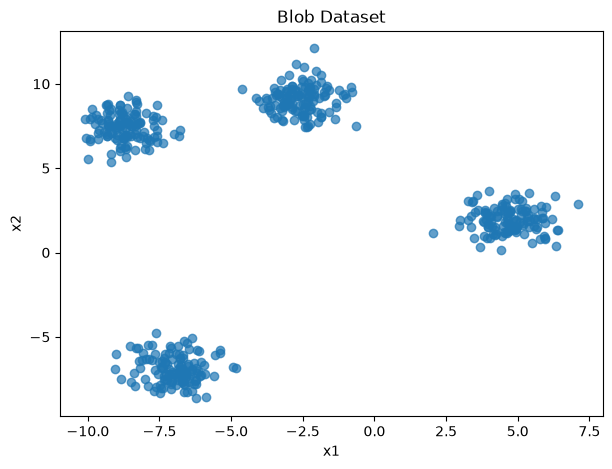

In [5]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_blobs["x1"],
    X_blobs["x2"],
    alpha=0.7
)

plt.title("Blob Dataset")
plt.xlabel("x1")
plt.ylabel("x2")

plt.show()

In [7]:
results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(
        X_blobs
    )

    inertia = model.inertia_

    silhouette = silhouette_score(
        X_blobs,
        labels
    )

    results.append(
        {
            "k": k,
            "inertia": inertia,
            "silhouette": silhouette
        }
    )

results_df = pd.DataFrame(results)

print(results_df)


   k       inertia  silhouette
0  2  15385.936334    0.607231
1  3   3124.987478    0.781919
2  4    607.289820    0.833614
3  5    547.808689    0.700468
4  6    492.360287    0.563530
5  7    435.882670    0.450574
6  8    380.463106    0.348880


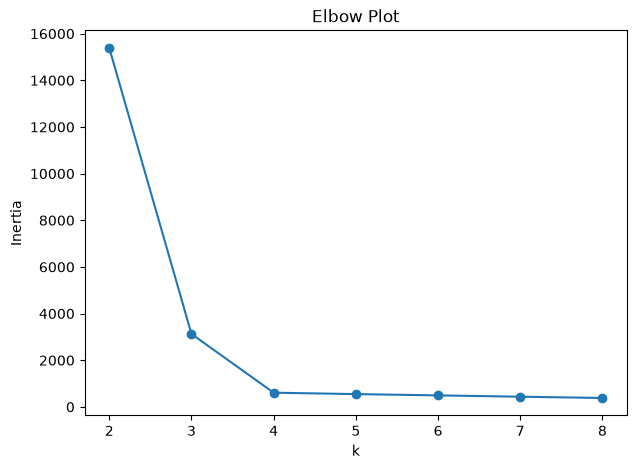

In [9]:
plt.figure(figsize=(7, 5))

plt.plot(
    results_df["k"],
    results_df["inertia"],
    marker="o"
)

plt.title("Elbow Plot")
plt.xlabel("k")
plt.ylabel("Inertia")

plt.show()


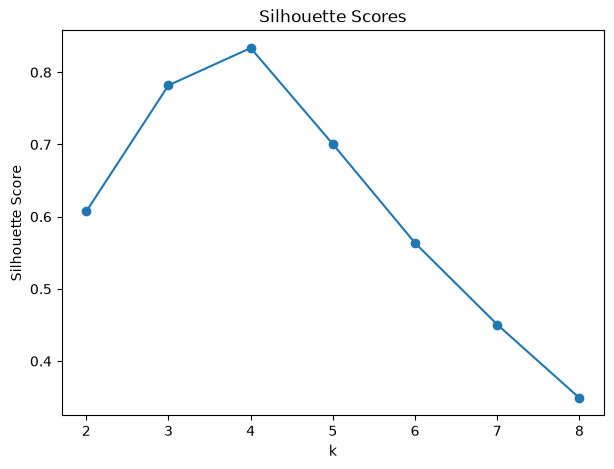

In [10]:
plt.figure(figsize=(7, 5))

plt.plot(
    results_df["k"],
    results_df["silhouette"],
    marker="o"
)

plt.title("Silhouette Scores")
plt.xlabel("k")
plt.ylabel("Silhouette Score")

plt.show()

## B1 Conclusion

The elbow plot suggests that k = 4 is a good choice because inertia decreases rapidly until k = 4 and then begins to level off.

The silhouette score is highest at k = 4, indicating that the observations fit their assigned clusters well and are separated from other clusters.

Based on both the elbow plot and silhouette scores, I selected k = 4.

The resulting clusters appear useful because they match the four visible groups in the scatter plot. However, the plots alone cannot determine what real-world categories the groups would represent.

In [11]:
moons = clustering_data[
    clustering_data["experiment"] == "moons"
]

print(moons.shape)

X_moons = moons[["x1", "x2"]]

(1000, 4)


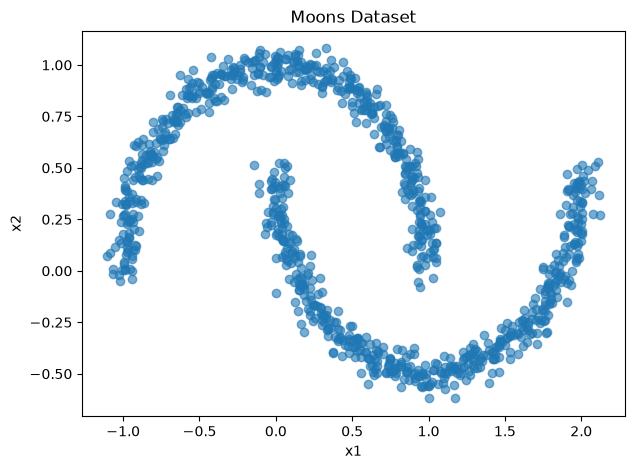

In [12]:
plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons["x1"],
    X_moons["x2"],
    alpha=0.6
)

plt.title("Moons Dataset")
plt.xlabel("x1")
plt.ylabel("x2")

plt.show()

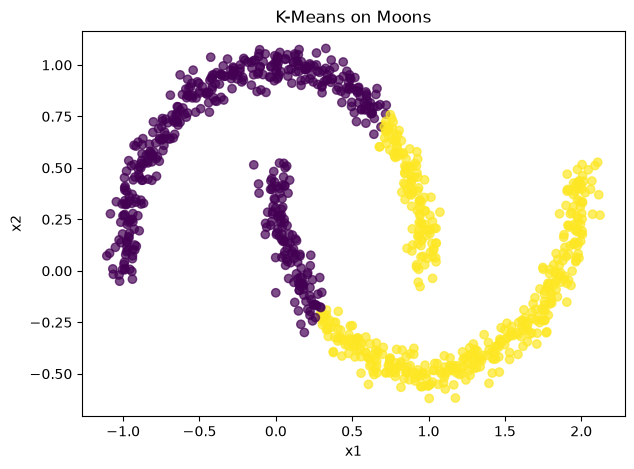

In [13]:
kmeans_moons = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)

kmeans_labels = kmeans_moons.fit_predict(
    X_moons
)

plt.figure(figsize=(7, 5))

plt.scatter(
    X_moons["x1"],
    X_moons["x2"],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

plt.title("K-Means on Moons")
plt.xlabel("x1")
plt.ylabel("x2")

plt.show()

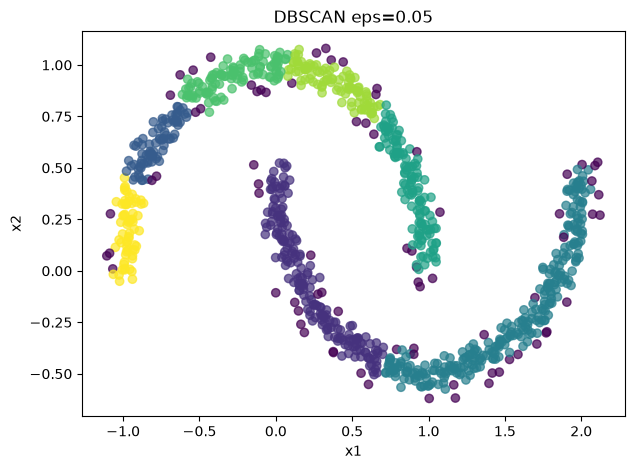

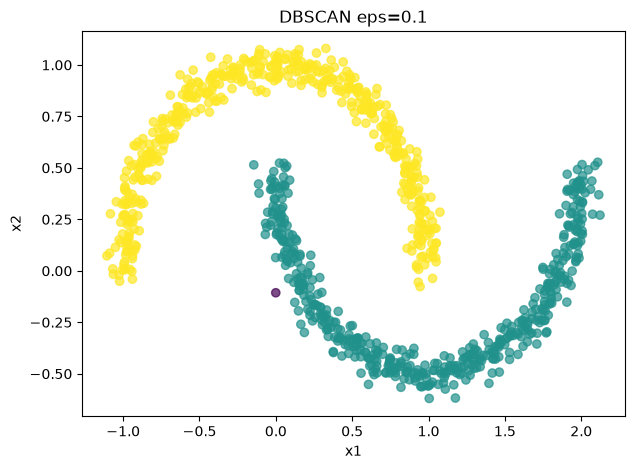

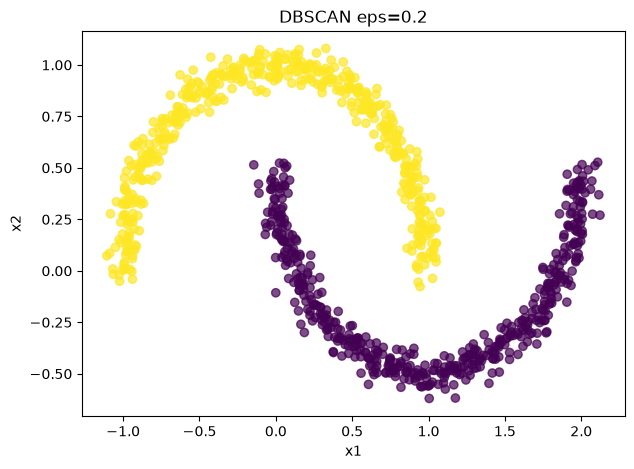

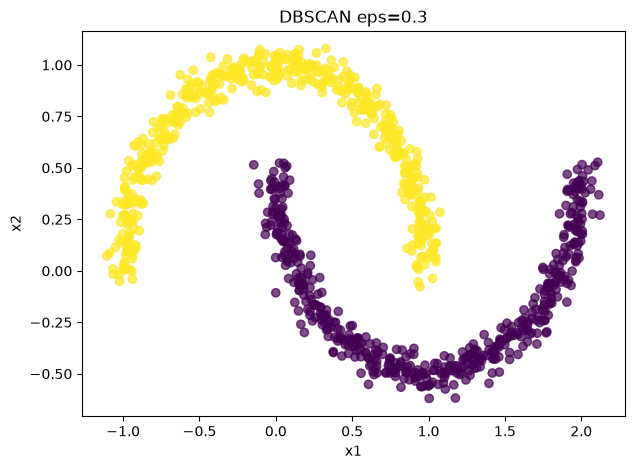

In [16]:
from sklearn.cluster import DBSCAN

dbscan_results = []

for eps in [0.05, 0.10, 0.20, 0.30]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_moons)

    cluster_count = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    noise_count = list(labels).count(-1)

    noise_percent = (
        noise_count / len(labels)
    ) * 100

    dbscan_results.append(
        {
            "eps": eps,
            "clusters": cluster_count,
            "noise_points": noise_count,
            "noise_percent": round(
                noise_percent,
                2
            )
        }
    )

    plt.figure(figsize=(7, 5))

    plt.scatter(
        X_moons["x1"],
        X_moons["x2"],
        c=labels,
        cmap="viridis",
        alpha=0.7
    )

    plt.title(f"DBSCAN eps={eps}")

    plt.xlabel("x1")
    plt.ylabel("x2")

    plt.show()


In [17]:
dbscan_df = pd.DataFrame(
    dbscan_results
)

print(dbscan_df)

    eps  clusters  noise_points  noise_percent
0  0.05         7            77            7.7
1  0.10         2             1            0.1
2  0.20         2             0            0.0
3  0.30         2             0            0.0


## B2 Comparison

When eps was 0.05, DBSCAN created 7 clusters and labeled 77 points as noise. The neighborhood size was too small and many observations were not connected.

As eps increased to 0.10, 0.20, and 0.30, DBSCAN found 2 clusters and very few or no noise points.

The eps = 0.10 result best follows the crescent shapes while still identifying the two main groups.

K-Means divided the moons using a straight boundary because it assumes roughly round clusters. DBSCAN follows the curved crescent shapes because it is based on density rather than distance to a centroid.

A noise label does not prove a point is invalid. It only means the point does not belong to a dense region under the chosen settings.

DBSCAN does not provide a standard predict method because cluster assignments depend on neighboring observations available during fitting.

In [18]:
faces = pd.read_csv(
    r"C:\Chapter8UnsupervisedLearning\olivetti_faces.csv"
)

print(faces.shape)

print(faces.head())

(400, 4097)
   identity   pixel_0   pixel_1   pixel_2   pixel_3   pixel_4   pixel_5  \
0         0  0.309917  0.367769  0.417355  0.442149  0.528926  0.607438   
1         0  0.454545  0.471074  0.512397  0.557851  0.595041  0.640496   
2         0  0.318182  0.400826  0.491736  0.528926  0.586777  0.657025   
3         0  0.198347  0.194215  0.194215  0.194215  0.190083  0.190083   
4         0  0.500000  0.545455  0.582645  0.623967  0.648760  0.690083   

    pixel_6   pixel_7   pixel_8  ...  pixel_4086  pixel_4087  pixel_4088  \
0  0.657025  0.677686  0.690083  ...    0.665289    0.669421    0.652893   
1  0.681818  0.702479  0.710744  ...    0.136364    0.157025    0.136364   
2  0.681818  0.685950  0.702479  ...    0.074380    0.132231    0.181818   
3  0.243802  0.404959  0.483471  ...    0.652893    0.636364    0.657025   
4  0.694215  0.714876  0.723140  ...    0.190083    0.161157    0.177686   

   pixel_4089  pixel_4090  pixel_4091  pixel_4092  pixel_4093  pixel_4094  \
0  

In [19]:
print(
    "Rows:",
    len(faces)
)

print(
    "Columns:",
    len(faces.columns)
)

print(
    "Unique identities:",
    faces["identity"].nunique()
)

Rows: 400
Columns: 4097
Unique identities: 40


In [20]:
X_faces = faces.drop(
    columns=["identity"]
)

y_faces = faces["identity"]

print(X_faces.shape)

print(y_faces.shape)

(400, 4096)
(400,)


In [21]:
from sklearn.model_selection import train_test_split

X_dev_faces, X_test_faces, y_dev_faces, y_test_faces = (
    train_test_split(
        X_faces,
        y_faces,
        stratify=y_faces,
        test_size=0.20,
        random_state=42
    )
)

X_train_faces, X_valid_faces, y_train_faces, y_valid_faces = (
    train_test_split(
        X_dev_faces,
        y_dev_faces,
        stratify=y_dev_faces,
        test_size=0.25,
        random_state=42
    )
)

print(
    len(X_train_faces),
    len(X_valid_faces),
    len(X_test_faces)
)

240 80 80


In [22]:
print("Training Counts")

print(
    y_train_faces
    .value_counts()
    .sort_index()
)

print("\nValidation Counts")

print(
    y_valid_faces
    .value_counts()
    .sort_index()
)

print("\nTest Counts")

print(
    y_test_faces
    .value_counts()
    .sort_index()
)

Training Counts
identity
0     6
1     6
2     6
3     6
4     6
5     6
6     6
7     6
8     6
9     6
10    6
11    6
12    6
13    6
14    6
15    6
16    6
17    6
18    6
19    6
20    6
21    6
22    6
23    6
24    6
25    6
26    6
27    6
28    6
29    6
30    6
31    6
32    6
33    6
34    6
35    6
36    6
37    6
38    6
39    6
Name: count, dtype: int64

Validation Counts
identity
0     2
1     2
2     2
3     2
4     2
5     2
6     2
7     2
8     2
9     2
10    2
11    2
12    2
13    2
14    2
15    2
16    2
17    2
18    2
19    2
20    2
21    2
22    2
23    2
24    2
25    2
26    2
27    2
28    2
29    2
30    2
31    2
32    2
33    2
34    2
35    2
36    2
37    2
38    2
39    2
Name: count, dtype: int64

Test Counts
identity
0     2
1     2
2     2
3     2
4     2
5     2
6     2
7     2
8     2
9     2
10    2
11    2
12    2
13    2
14    2
15    2
16    2
17    2
18    2
19    2
20    2
21    2
22    2
23    2
24    2
25    2
26    2
27    2
28    2
2

In [23]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_results = []

for k in [10, 20, 30, 40, 50]:

    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = model.fit_predict(
        X_train_faces
    )

    inertia = model.inertia_

    silhouette = silhouette_score(
        X_train_faces,
        labels
    )

    k_results.append(
        {
            "k": k,
            "inertia": inertia,
            "silhouette": silhouette
        }
    )

k_df = pd.DataFrame(k_results)

print(k_df)

    k       inertia  silhouette
0  10  11328.700992    0.088747
1  20   9420.662419    0.098495
2  30   7958.597129    0.124757
3  40   6772.464836    0.153712
4  50   5829.563589    0.170972


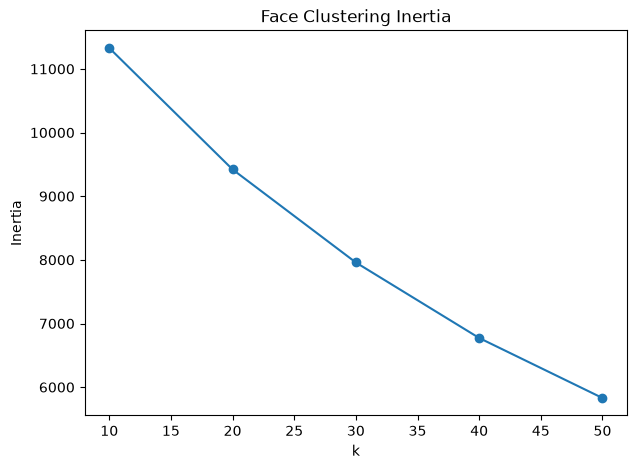

In [25]:
plt.figure(figsize=(7,5))

plt.plot(
    k_df["k"],
    k_df["inertia"],
    marker="o"
)

plt.title("Face Clustering Inertia")
plt.xlabel("k")
plt.ylabel("Inertia")

plt.show()

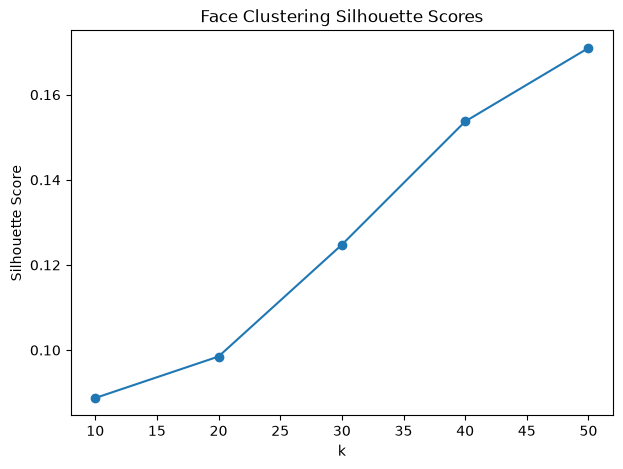

In [26]:
plt.figure(figsize=(7,5))

plt.plot(
    k_df["k"],
    k_df["silhouette"],
    marker="o"
)

plt.title("Face Clustering Silhouette Scores")
plt.xlabel("k")
plt.ylabel("Silhouette Score")

plt.show()

## C1 Conclusion

The silhouette score increased as k increased and reached its highest value at k = 50.

The inertia also continued to decrease as more clusters were added.

Based on the available metrics, I selected k = 50 because it provided the highest silhouette score among the candidate values.

The selected k does not need to equal the 40 face identities because clustering may group images by lighting, pose, expression, or other visual similarities rather than by person identity alone.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

baseline_classifier = LogisticRegression(
    C=1.0,
    max_iter=5000,
    random_state=42
)

baseline_classifier.fit(
    X_train_faces,
    y_train_faces
)

baseline_predictions = baseline_classifier.predict(
    X_valid_faces
)

baseline_accuracy = accuracy_score(
    y_valid_faces,
    baseline_predictions
)

print(
    "Baseline Validation Accuracy:",
    round(baseline_accuracy, 4)
)

Baseline Validation Accuracy: 0.9625


In [28]:
selected_k = 50

kmeans_faces = KMeans(
    n_clusters=selected_k,
    n_init=10,
    random_state=42
)

kmeans_faces.fit(
    X_train_faces
)

train_distances = kmeans_faces.transform(
    X_train_faces
)

valid_distances = kmeans_faces.transform(
    X_valid_faces
)

print(train_distances.shape)
print(valid_distances.shape)

(240, 50)
(80, 50)


In [29]:
from sklearn.preprocessing import StandardScaler

distance_scaler = StandardScaler()

train_distances_scaled = (
    distance_scaler.fit_transform(
        train_distances
    )
)

valid_distances_scaled = (
    distance_scaler.transform(
        valid_distances
    )
)

In [30]:
distance_classifier = LogisticRegression(
    C=1.0,
    max_iter=5000,
    random_state=42
)

distance_classifier.fit(
    train_distances_scaled,
    y_train_faces
)

distance_predictions = (
    distance_classifier.predict(
        valid_distances_scaled
    )
)

distance_accuracy = accuracy_score(
    y_valid_faces,
    distance_predictions
)

print(
    "Distance Feature Accuracy:",
    round(distance_accuracy, 4)
)


Distance Feature Accuracy: 0.875


In [31]:
combined_train = np.hstack(
    [
        X_train_faces,
        train_distances
    ]
)

combined_valid = np.hstack(
    [
        X_valid_faces,
        valid_distances
    ]
)

combined_scaler = StandardScaler()

combined_train_scaled = (
    combined_scaler.fit_transform(
        combined_train
    )
)

combined_valid_scaled = (
    combined_scaler.transform(
        combined_valid
    )
)

combined_classifier = LogisticRegression(
    C=1.0,
    max_iter=5000,
    random_state=42
)

combined_classifier.fit(
    combined_train_scaled,
    y_train_faces
)

combined_predictions = (
    combined_classifier.predict(
        combined_valid_scaled
    )
)

combined_accuracy = accuracy_score(
    y_valid_faces,
    combined_predictions
)

print(
    "Combined Feature Accuracy:",
    round(combined_accuracy, 4)
)

Combined Feature Accuracy: 0.95


In [32]:
comparison_table = pd.DataFrame(
    [
        {
            "Representation": "Raw Pixels",
            "Features": 4096,
            "Validation Accuracy":
                baseline_accuracy
        },
        {
            "Representation": "Cluster Distances",
            "Features": 50,
            "Validation Accuracy":
                distance_accuracy
        },
        {
            "Representation": "Combined Features",
            "Features": 4096 + 50,
            "Validation Accuracy":
                combined_accuracy
        }
    ]
)

print(
    comparison_table
)

      Representation  Features  Validation Accuracy
0         Raw Pixels      4096               0.9625
1  Cluster Distances        50               0.8750
2  Combined Features      4146               0.9500


## C2 Model Selection

The Raw Pixel representation achieved the highest validation accuracy of 0.9625.

The Combined Feature representation achieved a validation accuracy of 0.9500.

The Cluster Distance representation achieved a validation accuracy of 0.8750.

Because the Raw Pixel representation produced the highest validation accuracy, it was selected as the final model.

The clustering features did not improve classification performance in this experiment.

In [33]:
final_classifier = LogisticRegression(
    C=1.0,
    max_iter=5000,
    random_state=42
)

final_classifier.fit(
    X_dev_faces,
    y_dev_faces
)

final_test_predictions = (
    final_classifier.predict(
        X_test_faces
    )
)

final_test_accuracy = accuracy_score(
    y_test_faces,
    final_test_predictions
)

print(
    "Final Test Accuracy:",
    round(
        final_test_accuracy,
        4
    )
)

print(
    "Correct Predictions:",
    (
        final_test_predictions
        ==
        y_test_faces
    ).sum()
)

Final Test Accuracy: 0.975
Correct Predictions: 78


## C2 Final Result

The Raw Pixel representation was selected because it achieved the highest validation accuracy.

The final model was evaluated once on the reserved test set.

In this experiment, cluster distance features did not improve classification performance compared to using the original face pixels.

In [34]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=0.99,
    svd_solver="full"
)

pca.fit(X_train_faces)

X_train_pca = pca.transform(
    X_train_faces
)

X_valid_pca = pca.transform(
    X_valid_faces
)

print(
    "Components:",
    pca.n_components_
)

print(
    "Variance Retained:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Components: 176
Variance Retained: 0.9901


## C3 PCA

PCA was fitted using only the training images.

The reduced representation retains approximately 99 percent of the original variance while using fewer dimensions.

Reducing dimensions makes Gaussian Mixture Models more practical for high-dimensional face data.

In [35]:
from sklearn.mixture import GaussianMixture

gmm_results = []

for n in [1, 2, 5, 10]:

    gmm = GaussianMixture(
        n_components=n,
        covariance_type="diag",
        n_init=5,
        max_iter=300,
        reg_covar=1e-5,
        random_state=42
    )

    gmm.fit(X_train_pca)

    gmm_results.append(
        {
            "components": n,
            "converged": gmm.converged_,
            "BIC": gmm.bic(X_train_pca),
            "AIC": gmm.aic(X_train_pca)
        }
    )

gmm_df = pd.DataFrame(gmm_results)

print(gmm_df)

   components  converged           BIC           AIC
0           1       True  26695.862444  25470.677543
1           2       True  26900.019933  24446.169493
2           5       True  30937.255698  24797.408637
3          10       True  38932.623057  26649.448296


## C3 Gaussian Mixtures

Gaussian Mixture Models were fit using PCA-reduced features instead of the original 4096 face pixels.

Using PCA reduces dimensionality and makes the density estimation problem more manageable.

The model with the lowest BIC will be selected if it successfully converged.

In [39]:
from sklearn.mixture import GaussianMixture

gmm_results = []

for n in [1, 2, 5, 10]:

    gmm = GaussianMixture(
        n_components=n,
        covariance_type="diag",
        n_init=5,
        max_iter=300,
        reg_covar=1e-5,
        random_state=42
    )

    gmm.fit(X_train_pca)

    gmm_results.append(
        {
            "components": n,
            "converged": gmm.converged_,
            "BIC": gmm.bic(X_train_pca),
            "AIC": gmm.aic(X_train_pca)
        }
    )

gmm_df = pd.DataFrame(gmm_results)

print(gmm_df)

   components  converged           BIC           AIC
0           1       True  26695.862444  25470.677543
1           2       True  26900.019933  24446.169493
2           5       True  30937.255698  24797.408637
3          10       True  38932.623057  26649.448296


In [40]:
best_components = 1

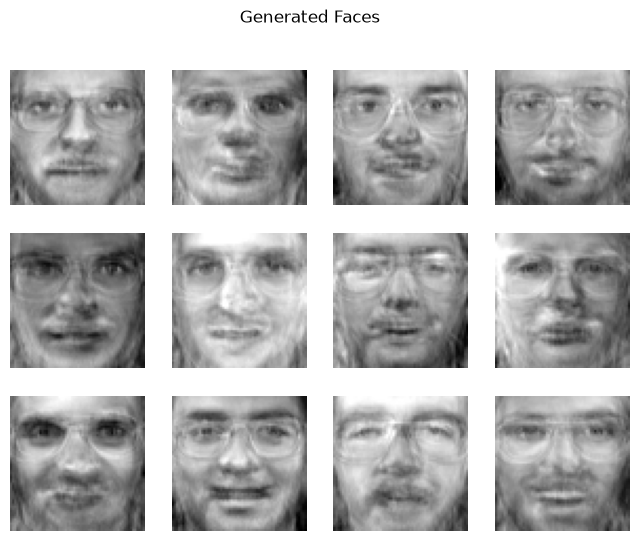

In [41]:
best_gmm = GaussianMixture(
    n_components=best_components,
    covariance_type="diag",
    n_init=5,
    max_iter=300,
    reg_covar=1e-5,
    random_state=42
)

best_gmm.fit(X_train_pca)

generated_faces, component_labels = (
    best_gmm.sample(12)
)

generated_images = pca.inverse_transform(
    generated_faces
)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(8, 6)
)

for ax, image in zip(
    axes.ravel(),
    generated_images
):
    ax.imshow(
        image.reshape(64, 64),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("Generated Faces")
plt.show()

## C3 Generated Faces

The generated faces were created by sampling from the selected Gaussian Mixture Model and transforming the samples back into image space.

The generated images may appear blurry because the model is learning overall patterns rather than reproducing exact faces.

Gaussian Mixture Models estimate probability distributions and therefore generate approximate representations of the training data.

In [42]:
validation_scores = best_gmm.score_samples(
    X_valid_pca
)

print(
    "Validation Score Statistics"
)

print(
    pd.Series(
        validation_scores
    ).describe()
)

Validation Score Statistics
count    80.000000
mean    -30.311932
std      18.704846
min     -80.538247
25%     -40.828120
50%     -26.285579
75%     -17.873964
max       1.759510
dtype: float64


In [43]:
threshold = np.percentile(
    validation_scores,
    5
)

print(
    "5th Percentile Threshold:",
    threshold
)

5th Percentile Threshold: -65.18622969335411


## C3 Anomaly Threshold

The anomaly threshold was selected using the 5th percentile of validation face scores.

Faces scoring below this threshold are considered less typical under the fitted Gaussian Mixture Model.

This threshold is exploratory and does not represent a known defect rate.

## C3 Threshold Selection

The 5th percentile threshold was selected using validation face scores.

The threshold value was -65.186.

Faces scoring below this threshold are considered less typical under the fitted Gaussian Mixture Model.

This threshold is exploratory and does not represent a confirmed defect rate.

In [44]:
validation_flags = (
    validation_scores < threshold
)

print(
    "Validation Faces Flagged:",
    validation_flags.sum()
)

print(
    "Validation Flag Rate:",
    round(
        validation_flags.mean() * 100,
        2
    ),
    "%"
)

Validation Faces Flagged: 4
Validation Flag Rate: 5.0 %


## C3 Validation Results

Approximately five percent of the validation faces were flagged because the threshold was defined using the fifth percentile.

These flagged observations have lower probability under the Gaussian Mixture Model and are considered less typical than the majority of validation faces.

In [45]:
X_test_pca = pca.transform(
    X_test_faces
)

test_scores = best_gmm.score_samples(
    X_test_pca
)

test_flags = test_scores < threshold

print(
    "Test Faces Flagged:",
    test_flags.sum()
)

print(
    "Test Flag Rate:",
    round(
        test_flags.mean() * 100,
        2
    ),
    "%"
)

Test Faces Flagged: 4
Test Flag Rate: 5.0 %


## C3 Test Results

The frozen threshold was applied to the reserved test set without modification.

Four test faces were flagged as unusual, resulting in a test flag rate of 5.0%.

The test flag rate matched the validation flag rate, suggesting that the threshold generalized consistently to unseen data.

This result should be interpreted as an exploratory anomaly detection experiment rather than a guaranteed detection rate.


In [46]:
train_reconstructed = pca.inverse_transform(
    X_train_pca
)

train_errors = np.mean(
    (
        X_train_faces.to_numpy()
        - train_reconstructed
    ) ** 2,
    axis=1
)

print(
    "Training Reconstruction Error Statistics"
)

print(
    pd.Series(
        train_errors
    ).describe()
)

Training Reconstruction Error Statistics
count    240.000000
mean       0.000191
std        0.000111
min        0.000013
25%        0.000079
50%        0.000196
75%        0.000288
max        0.000425
dtype: float64


In [47]:
valid_reconstructed = pca.inverse_transform(
    X_valid_pca
)

valid_errors = np.mean(
    (
        X_valid_faces.to_numpy()
        - valid_reconstructed
    ) ** 2,
    axis=1
)

print(
    "Validation Reconstruction Error Statistics"
)

print(
    pd.Series(
        valid_errors
    ).describe()
)

Validation Reconstruction Error Statistics
count    80.000000
mean      0.002253
std       0.001048
min       0.000697
25%       0.001355
50%       0.001981
75%       0.003104
max       0.005050
dtype: float64


In [48]:
reconstruction_threshold = np.percentile(
    valid_errors,
    95
)

print(
    "Reconstruction Threshold:",
    reconstruction_threshold
)

Reconstruction Threshold: 0.0038770033915043888


In [49]:
validation_reconstruction_flags = (
    valid_errors > reconstruction_threshold
)

print(
    "Validation Images Flagged:",
    validation_reconstruction_flags.sum()
)

print(
    "Validation Flag Rate:",
    round(
        validation_reconstruction_flags.mean() * 100,
        2
    ),
    "%"
)

Validation Images Flagged: 4
Validation Flag Rate: 5.0 %


## C4 Reconstruction Threshold

The reconstruction threshold was selected using the 95th percentile of validation reconstruction errors.

Images with reconstruction errors above this threshold are considered unusual because PCA is unable to reconstruct them as accurately.

Higher reconstruction error indicates that the image differs more from the patterns learned during training.

In [52]:
X_test_pca = pca.transform(
    X_test_faces
)

test_reconstructed = pca.inverse_transform(
    X_test_pca
)

test_errors = np.mean(
    (
        X_test_faces.to_numpy()
        - test_reconstructed
    ) ** 2,
    axis=1
)

test_flags = (
    test_errors >
    reconstruction_threshold
)

print(
    "Test Images Flagged:",
    test_flags.sum()
)

print(
    "Test Flag Rate:",
    round(
        test_flags.mean() * 100,
        2
    ),
    "%"
)

Test Images Flagged: 8
Test Flag Rate: 10.0 %


## C4 Reconstruction Results

The reconstruction threshold was selected using the validation set and then frozen before evaluating the test set.

Eight test faces were flagged, resulting in a test flag rate of 10.0%.

Reconstruction error identifies unusual images by measuring how accurately PCA can reconstruct them. Images with larger reconstruction errors differ more from the patterns learned during training.

# Final Reflection

For compact groups, I would choose K-Means because it works well when clusters are relatively round and clearly separated. One limitation is that K-Means struggles with irregularly shaped clusters.

For curved groups, I would choose DBSCAN because it successfully followed the crescent moon shapes. One limitation is that DBSCAN is sensitive to parameter choices such as eps.

For unusual face images, I would use PCA reconstruction error and Gaussian Mixture Models together. Reconstruction error identifies images that differ from the learned PCA representation, while Gaussian Mixture Models identify images with low probability under the learned distribution. One limitation is that unusual scores do not necessarily mean an image is invalid.